# Data Analysis about Turning Machining Experiments

In [1]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

### Loading data

In [2]:
# File data CSV -> C:= cutting; NC := NON-cutting
filedataC150 = 'ANNACHPTVC150.csv'
filedataNC150 = 'ANNACHPTVC150VIDE.csv'
filedataC1200 = 'ANNACHPT1200RPM.csv'
filedataNC1200 = 'ANNACHPT1200RPMVIDE.csv'

In [3]:
# Reading csv
dfC150 = pd.read_csv(filedataC150, skiprows=10)
dfNC150 = pd.read_csv(filedataNC150, skiprows=10)
dfC1200 = pd.read_csv(filedataC1200, skiprows=10)
dfNC1200 = pd.read_csv(filedataNC1200, skiprows=10)

In [4]:
# Naming columns
dfC150.columns = [
    'time',
    'power',
    'prog_pos_z',   # Programmed position
    'prog_pos_x',
    'meas_pos_z',   # Actual value of position 
    'meas_pos_x',
    'spindle1'  # Spindle speed. Only the first data does not have the spindle 2 data
]

cols = ['time', 'power', 'prog_pos_z', 'prog_pos_x',
        'meas_pos_z', 'meas_pos_x', 'spindle1', 'spindle2']
for df in [dfNC150, dfC1200, dfNC1200]:
    df.columns = cols

In [5]:
# Defining indecis of columns
cols_to_convert = dfC150.columns.difference(['time'])

# Conversion to numeric type
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    for col in cols_to_convert:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Suppressing Nan columns
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    df.dropna(inplace=True)

### Energetic calculation

In [6]:
# Calculating dt
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    df['delta_t'] = df['time'].diff()
    df.loc[df.index[0], 'delta_t'] = 0

In [7]:
# Instantaneous energy (W x s / 1000 = kJ)
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    df['energy_kJ'] = df['power'] * df['delta_t'] / 1000

In [8]:
# Accumulated energy (kJ)
for df in [dfC150, dfNC150, dfC1200, dfNC1200]:
    df['energy_kJ_cum'] = df['energy_kJ'].cumsum()

In [9]:
# Group energy by programmed X position
energy_by_x_C150 = dfC150.groupby('prog_pos_x')['energy_kJ'].sum().reset_index()
Filt_energy_by_x_C150 = energy_by_x_C150[energy_by_x_C150['energy_kJ'] > 0.15]  # Filters energy to suppress noise effects

energy_by_x_NC150 = dfNC150.groupby('prog_pos_x')['energy_kJ'].sum().reset_index()
Filt_energy_by_x_NC150 = energy_by_x_NC150[energy_by_x_NC150['energy_kJ'] > 0.15]

energy_by_x_C1200 = dfC1200.groupby('prog_pos_x')['energy_kJ'].sum().reset_index()
Filt_energy_by_x_C1200 = energy_by_x_C1200[energy_by_x_C1200['energy_kJ'] > 0.15]

energy_by_x_NC1200 = dfNC1200.groupby('prog_pos_x')['energy_kJ'].sum().reset_index()
Filt_energy_by_x_NC1200 = energy_by_x_NC1200[energy_by_x_NC1200['energy_kJ'] > 0.15]

### Programmed position graphes

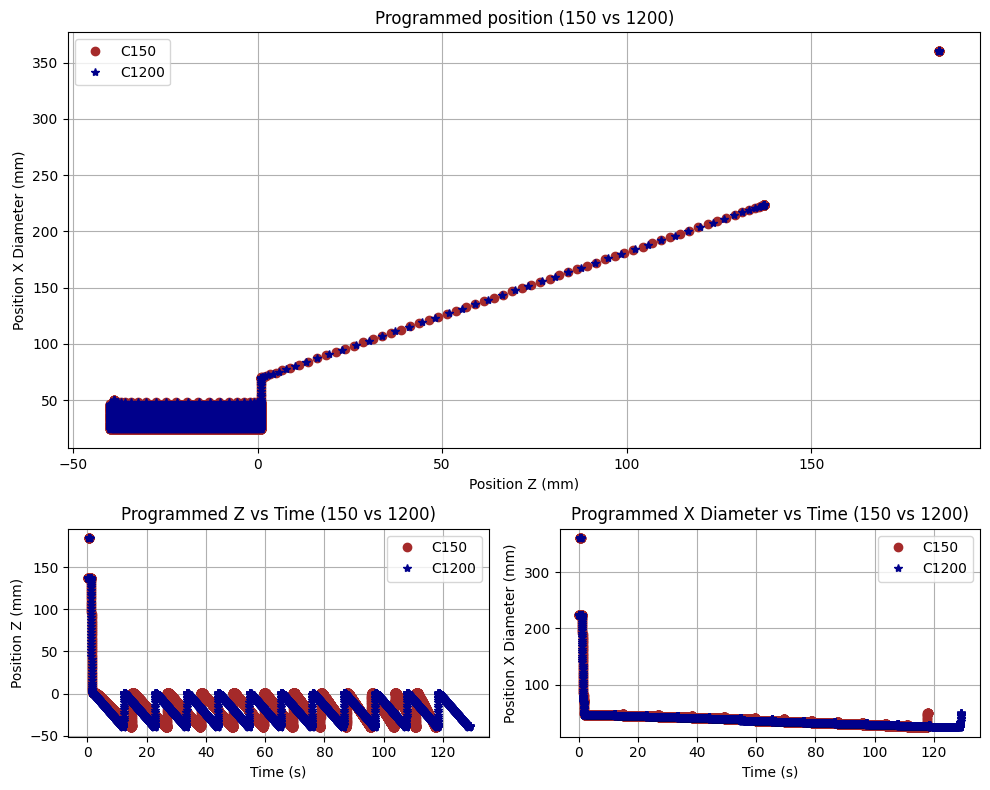

In [10]:
# Overall figure
fig = plt.figure(figsize=(10,8))
gs = gridspec.GridSpec(2, 2, height_ratios=[2,1])  # 2x2 grid

# Progammed positions X vs Z
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(dfC150['prog_pos_z'], dfC150['prog_pos_x'],
         label='C150', color='brown', marker='o', linestyle='none')
ax1.plot(dfC1200['prog_pos_z'], dfC1200['prog_pos_x'],
         label='C1200', color='darkblue', marker='*', linestyle='none')
ax1.set_xlabel('Position Z (mm)')
ax1.set_ylabel('Position X Diameter (mm)')
ax1.set_title('Programmed position (150 vs 1200)')

# Progammed position Z vs Time
ax2 = fig.add_subplot(gs[1, 0])
ax2.plot(dfC150['time'], dfC150['prog_pos_z'],
         label='C150', color='brown', marker='o', linestyle='none')
ax2.plot(dfC1200['time'], dfC1200['prog_pos_z'],
         label='C1200', color='darkblue', marker='*', linestyle='none')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Position Z (mm)')
ax2.set_title('Programmed Z vs Time (150 vs 1200)')

# Progammed position X Diameter vs Time
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(dfC150['time'], dfC150['prog_pos_x'],
         label='C150', color='brown', marker='o', linestyle='none')
ax3.plot(dfC1200['time'], dfC1200['prog_pos_x'],
         label='C1200', color='darkblue', marker='*', linestyle='none')
ax3.set_xlabel('Time (s)')
ax3.set_ylabel('Position X Diameter (mm)')
ax3.set_title('Programmed X Diameter vs Time (150 vs 1200)')

for ax in [ax1, ax2, ax3]:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


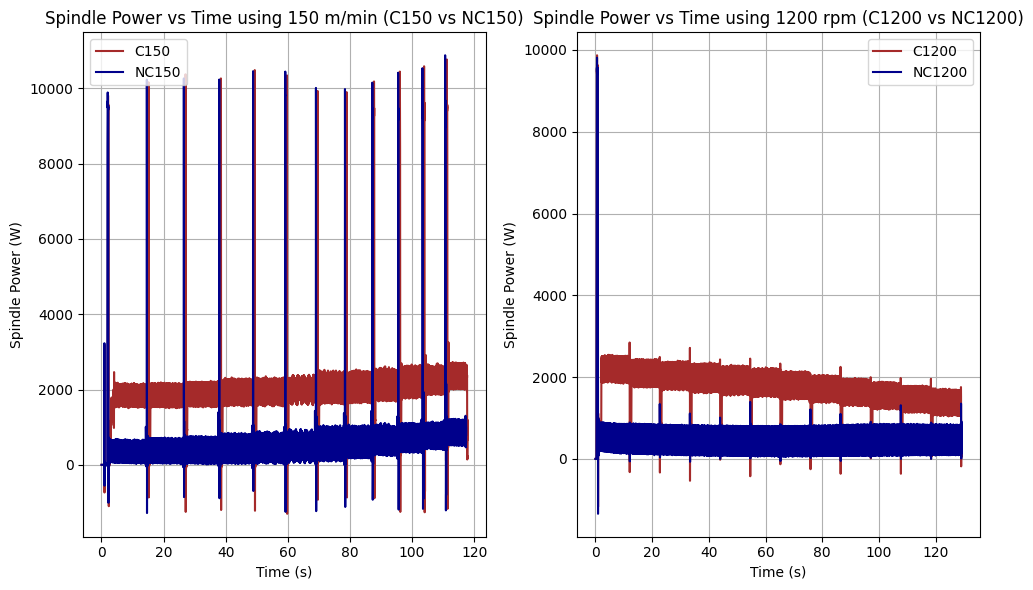

In [11]:
# Overall figure
fig = plt.figure(figsize=(10,6))
gs = gridspec.GridSpec(1, 2)

# Power vs Time using constant cutting velocity
ax1 = fig.add_subplot(gs[0,0])
ax1.plot(dfC150['time'], dfC150['power'], label='C150', color='brown') 
ax1.plot(dfNC150['time'], dfNC150['power'], label='NC150', color='darkblue')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Spindle Power (W)')
ax1.set_title('Spindle Power vs Time using 150 m/min (C150 vs NC150)')

# Power vs Time using constant spindle speed
ax2 = fig.add_subplot(gs[0,1])
ax2.plot(dfC1200['time'], dfC1200['power'], label='C1200', color='brown') 
ax2.plot(dfNC1200['time'], dfNC1200['power'], label='NC1200', color='darkblue')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Spindle Power (W)')
ax2.set_title('Spindle Power vs Time using 1200 rpm (C1200 vs NC1200)')

for ax in [ax1, ax2, ax3]:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()